In [1]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(seed=42)

sigma = 0.3
mu_y = 1
n = 1000

y = rng.normal(mu_y, sigma, n)

In [3]:
basic_model = pm.Model()

with basic_model:

    tau_0 = 0.5
    mu_0 = 1
    
    mu = pm.Normal("mu", mu = mu_0, sigma = tau_0) # prior

    y_obs = pm.Normal("y_obs", mu = mu, sigma=sigma, observed=y) 

    # step = pm.Metropolis()
    # step = pm.HamiltonianMC()

    step = pm.NUTS()
    idata = pm.sample(draws=2000, 
                      tune=500, 
                      chains=4,
                      step=step, 
                      random_seed=42)


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu]


Output()

Sampling 4 chains for 500 tune and 2_000 draw iterations (2_000 + 8_000 draws total) took 8 seconds.


In [4]:
idata.posterior["mu"].values.shape

(4, 2000)

In [5]:
# idata.sample_stats['accepted'].mean(dim='draw')

In [6]:
mu_samples = idata.posterior['mu'].values.flatten()

In [7]:
y_mean = y.mean()

tau_2 = 1/(n/sigma**2 + 1 / tau_0**2 )
mu_n = (n*y_mean/sigma**2 + mu_0/tau_0**2)/(1/tau_2)

In [8]:
print(rf"mu_n = {mu_n},   mu_muestral = {mu_samples.mean()}")

mu_n = 0.9913356538658243,   mu_muestral = 0.9914385319991628


In [9]:
print(rf"tau_n = {np.sqrt(tau_2)},   tau_muestral = {mu_samples.std()}")

tau_n = 0.009485125811490455,   tau_muestral = 0.009482073517651252


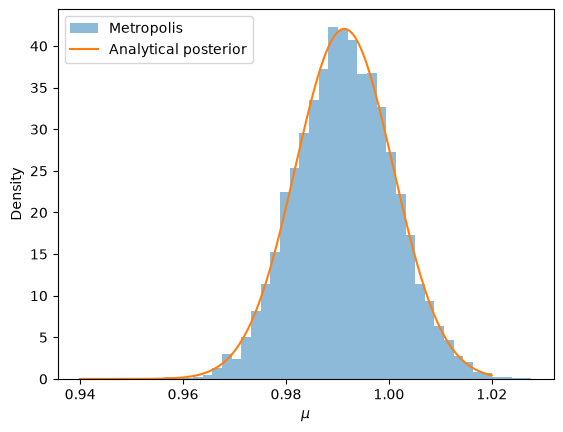

In [10]:
from scipy.stats import norm

x = np.linspace(0.94, 1.02, 300)

plt.hist(mu_samples, bins=40, density=True,
         alpha=0.5, label="Metropolis")

plt.plot(x, norm.pdf(x, mu_n, np.sqrt(tau_2)),
         label="Analytical posterior")

plt.xlabel(r"$\mu$")
plt.ylabel("Density")
plt.legend()
plt.show()

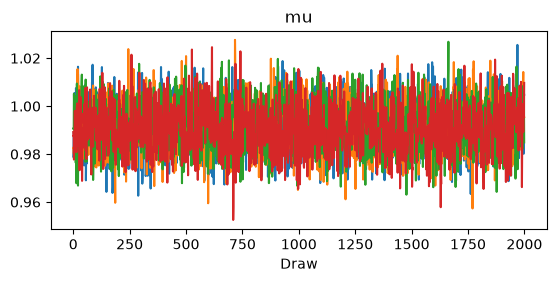

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,0.9914,0.0095,0.98,1,3177,4752,1.00,0.00017,9.7e-05


In [11]:
import arviz as az

az.plot_trace(idata, var_names=["mu"])
plt.show()

az.summary(idata, var_names=["mu"])